# deps

In [2]:
! dir
! python3 -m venv .venv
! source .venv/bin/activate
! pip install ipykernel matplotlib pandas scipy

data  ia  project.ipynb


In [2]:
# get the version of the package use

import sys

import matplotlib
import matplotlib.pyplot as pyplot
import pandas
import scipy

print("python     :", sys.version.split(' ')[0])
for module in (matplotlib, pandas, scipy):
    print(f"{module.__name__:<11}:", module.__version__)

python     : 3.13.5
matplotlib : 3.11.2
pandas     : 3.1.1
scipy      : 1.18.1


# Constant

In [31]:
DATA_PATH = "../data"
CSV_CLEAN = "boardGamesClean.csv"

#column name
TITLE = "Title"
ORIGINAL_TYPE = "Type 1"
TYPE = "Type"
COMPLEXITY = "Complexity"
MEAN_TIME = "Mean time"
ORIGINAL_AVERAGE_RATING = "Avg rating"
AVERAGE_RATING = "Average rating"

# Loading data

In [32]:
print(f"{DATA_PATH}/{CSV_CLEAN}")
df = pandas.read_csv(f"{DATA_PATH}/{CSV_CLEAN}")
df = df.rename(columns={ORIGINAL_TYPE: TYPE})
df = df.rename(columns={ORIGINAL_AVERAGE_RATING: AVERAGE_RATING})

#sort
df = df.sort_values(by=AVERAGE_RATING, ascending=True).reset_index(drop=True)

../data/boardGamesClean.csv


# Showing data

In [33]:
print("rows, columns:", df.shape)
df.info()
# affiche les x premiere ligne 
df.head(10)

rows, columns: (9744, 10)
<class 'pandas.DataFrame'>
RangeIndex: 9744 entries, 0 to 9743
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Title           9744 non-null   str    
 1   Average rating  9744 non-null   float64
 2   Complexity      9744 non-null   float64
 3   Min time        9744 non-null   float64
 4   Max time        9744 non-null   float64
 5   Min players     9744 non-null   float64
 6   Max players     9744 non-null   float64
 7   Num of voters   9744 non-null   int64  
 8   Type            9744 non-null   str    
 9   Mean time       9744 non-null   float64
dtypes: float64(7), int64(1), str(2)
memory usage: 761.4 KB


,Title,Average rating,Complexity,Min time,Max time,Min players,Max players,Num of voters,Type,Mean time
0,Feed the Woozle,5.42,1.00,15.0,15.0,2.0,5.0,111,Children's,15.0
1,Crash Pilot,5.43,1.13,20.0,20.0,2.0,5.0,112,Children's,20.0
2,Bounty Hunter: Shootout at the Saloon,5.44,1.89,10.0,10.0,2.0,2.0,158,Thematic,10.0
3,Chip-Chip Hurra!,5.44,1.10,20.0,30.0,2.0,4.0,121,Children's,25.0
4,Elephant's Trunk,5.46,1.00,15.0,15.0,2.0,4.0,157,Children's,15.0
5,Discover India,5.46,1.73,30.0,45.0,2.0,5.0,144,Family,37.5
6,Bugs,5.47,1.25,30.0,30.0,3.0,6.0,167,Family,30.0
7,Barking Up The Wrong Tree,5.47,1.30,10.0,30.0,2.0,5.0,129,Family,20.0
8,Hexxagon,5.47,1.93,20.0,20.0,2.0,2.0,147,Abstract,20.0
9,Enchanted Cupcake Party Game,5.48,1.00,10.0,20.0,2.0,5.0,135,Children's,15.0


In [34]:
cross_table = pandas.pivot_table(
    df,
    values=[AVERAGE_RATING, MEAN_TIME],
    index=[TYPE],
    aggfunc={"mean", "count"},
).round(2)

print(cross_table)

             Average rating       Mean time        
                      count  mean     count    mean
Type                                               
Abstract                709  6.53       709   29.29
Children's              404  6.26       404   20.28
Customizable            246  6.86       246   49.18
Family                 2801  6.59      2801   37.23
Party                   561  6.51       561   30.48
Strategy               2397  7.07      2397   86.70
Thematic               1107  7.04      1107   89.16
Wargames               1519  7.15      1519  178.43


## Graph

evolution of the rating

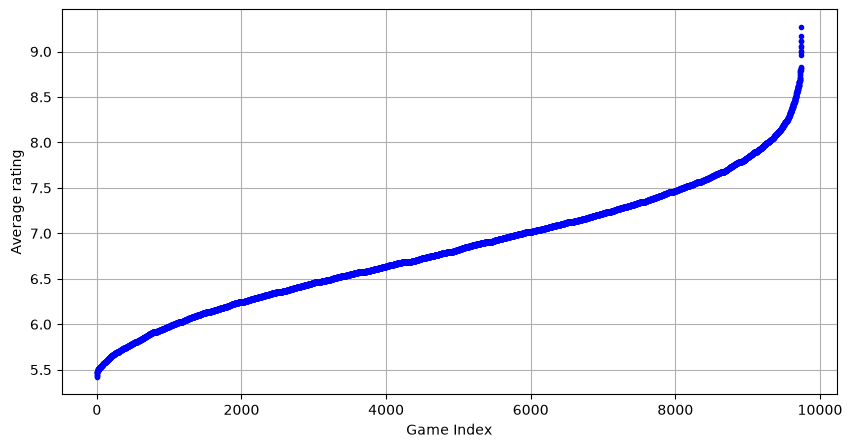

In [35]:
# print(df[AVERAGE_RATING])

# graph show the evolution of the average rating
pyplot.figure(figsize=(10, 5))
pyplot.plot(df[AVERAGE_RATING], color="b", marker=".", linestyle="none")
pyplot.xlabel("Game Index")
pyplot.ylabel(AVERAGE_RATING)
pyplot.grid(True)
pyplot.show()

# graph for number of games by type

game by type

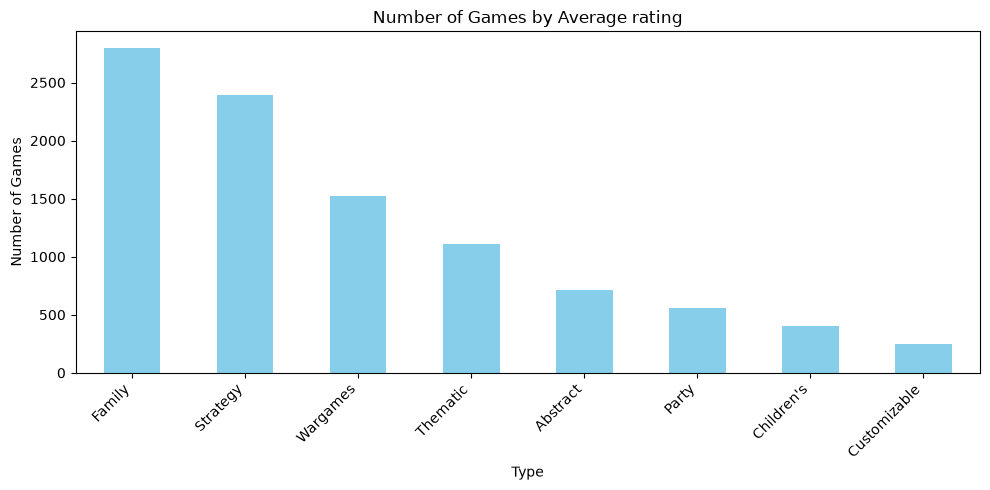

Type
Family          2801
Strategy        2397
Wargames        1519
Thematic        1107
Abstract         709
Party            561
Children's       404
Customizable     246
Name: count, dtype: int64


In [ ]:
pyplot.figure(figsize=(10, 5))
gameCountsByType = df[TYPE].value_counts()
gameCountsByType.plot(kind="bar", color="skyblue")
pyplot.xlabel(TYPE)
pyplot.ylabel("Number of Games")
pyplot.title(f"Number of Games by {TYPE}")
pyplot.xticks(rotation=45, ha="right")
pyplot.tight_layout() 
pyplot.show()
print(gameCountsByType)

mean time by game type

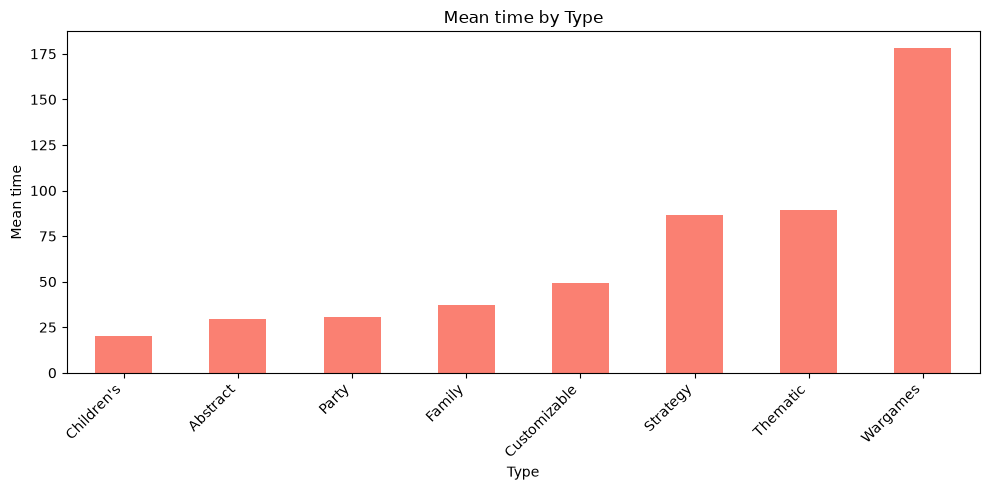

Type
Children's       20.280941
Abstract         29.291961
Party            30.475045
Family           37.225634
Customizable     49.176829
Strategy         86.696704
Thematic         89.162150
Wargames        178.427913
Name: Mean time, dtype: float64


In [37]:
pyplot.figure(figsize=(10, 5))
meanTimeByType = df.groupby(TYPE)[MEAN_TIME].mean().sort_values()
meanTimeByType.plot(kind="bar", color="salmon")
pyplot.xlabel(TYPE)
pyplot.ylabel(MEAN_TIME)
pyplot.title(f"{MEAN_TIME} by {TYPE}")
pyplot.xticks(rotation=45, ha="right")
pyplot.tight_layout() 
pyplot.show()
print(meanTimeByType)

average rating by type

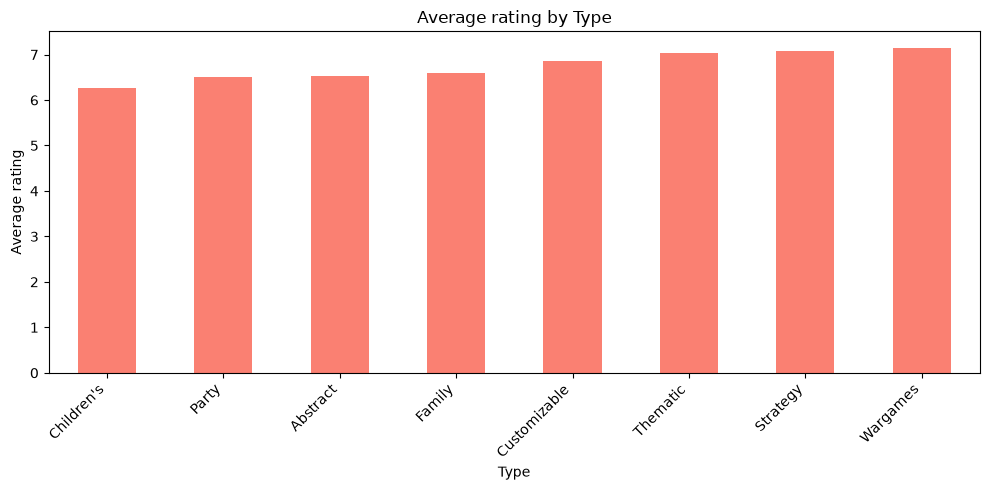

Type
Children's      6.255866
Party           6.505544
Abstract        6.532990
Family          6.594755
Customizable    6.863211
Thematic        7.035818
Strategy        7.073254
Wargames        7.152982
Name: Average rating, dtype: float64


In [38]:
pyplot.figure(figsize=(10, 5))
meanTimeByType = df.groupby(TYPE)[AVERAGE_RATING].mean().sort_values()
meanTimeByType.plot(kind="bar", color="salmon")
pyplot.xlabel(TYPE)
pyplot.ylabel(AVERAGE_RATING)
pyplot.title(f"{AVERAGE_RATING} by {TYPE}")
pyplot.xticks(rotation=45, ha="right")
pyplot.tight_layout() 
pyplot.show()
print(meanTimeByType)